# Нейросеть для предсказания калорийности блюд

Мультимодальная модель использует фотографию блюда, список ингредиентов и массу порции. Целевая задача — регрессия калорийности, основная метрика — MAE.

In [7]:
!pip install --force-reinstall --no-cache-dir \
    torch==2.9.1 \
    torchvision==0.24.1 \
    torchaudio==2.9.1 \
    --index-url https://download.pytorch.org/whl/cu126

Looking in indexes: https://download.pytorch.org/whl/cu126
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 47.4 MB/s  0:00:00 eta 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 897.7/897.7 kB 111.6 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 100.5 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 706.8/706.8 MB 92.4 MB/s  0:00:07:00:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 393.1/393.1 MB 88.6 MB/s  0:00:04ta 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200.2/200.2 MB 89.3 MB/s  0:00:02:00:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 88.4 MB/s  0:00:00 eta 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 158.2/158.2 MB 83.2 MB/s  0:00:01ta 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.6/216.6 MB 92.3 MB/s  0:00:02ta 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 287.2/287.2 MB 82.8 MB/s  0:00:03ta 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.3/322.3 MB 

In [1]:
from pathlib import Path
import os
import random
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

PROJECT_DIR = Path.cwd()
os.chdir(PROJECT_DIR)
print(f'Рабочая директория: {PROJECT_DIR}')

Рабочая директория: /home/froschin/work/masters_degree_Roshchin_M25-555/работа_с_изображениями_и_текстом/2


## 1. Загрузка и проверка данных

Технические ID ингредиентов заменяются на реальные названия в функции `prepare_metadata`. Изображение каждого блюда ищется по пути `data/images/<dish_id>/rgb.png`.

In [2]:
from dataset import prepare_metadata, split_metadata

metadata = prepare_metadata('data')
train_df, validation_df, test_df = split_metadata(metadata, val_size=0.15, seed=SEED)

print(f'Всего строк в dish.csv: {len(metadata):,}')
print(f'Строк с существующим изображением: {metadata.image_exists.sum():,}')
print(f'Отсутствующих изображений: {(~metadata.image_exists).sum():,}')
print(f'train: {len(train_df):,}, validation: {len(validation_df):,}, test: {len(test_df):,}')

display(metadata.head(3)[['dish_id', 'total_calories', 'total_mass', 'ingredient_text', 'split', 'image_exists']])
display(metadata.groupby('split').agg(
    dishes=('dish_id', 'count'),
    mean_calories=('total_calories', 'mean'),
    median_calories=('total_calories', 'median'),
    mean_mass=('total_mass', 'mean'),
).round(2))

/home/froschin/work/masters_degree_Roshchin_M25-555/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Всего строк в dish.csv: 3,262
Строк с существующим изображением: 3,262
Отсутствующих изображений: 0
train: 2,342, validation: 413, test: 507


,dish_id,total_calories,total_mass,ingredient_text,split,image_exists
0,dish_1561662216,300.794281,193.0,"soy sauce, garlic, white rice, parsley, onions...",test,True
1,dish_1561662054,419.438782,292.0,"pepper, white rice, mixed greens, garlic, soy ...",train,True
2,dish_1562008979,382.936646,290.0,"jalapenos, lemon juice, pork, wheat berry, cab...",test,True


,dishes,mean_calories,median_calories,mean_mass
split,,,,
test,507,255.47,226.01,198.51
train,2755,254.93,208.12,218.01


### Примеры изображений и ингредиентов

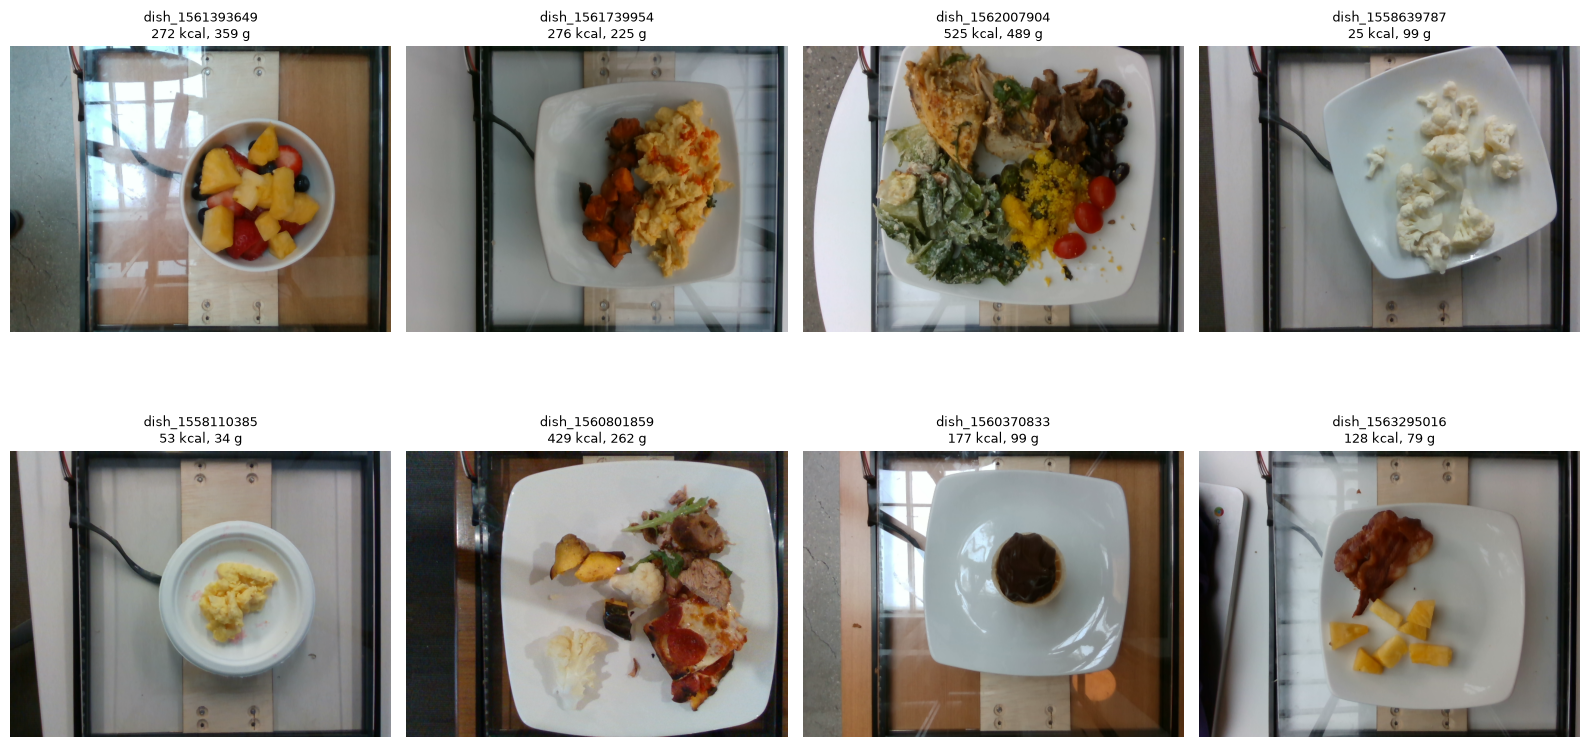

,dish_id,ingredient_text,total_calories,total_mass
2405,dish_1561393649,"berries, pineapple, cottage cheese",271.540009,359.0
134,dish_1561739954,"sweet potato, scrambled eggs",276.119995,225.0
411,dish_1562007904,"shallots, arugula, pepper, quinoa, mayonnaise,...",525.461365,489.0
203,dish_1558639787,cauliflower,24.750000,99.0
889,dish_1558110385,eggs,52.869999,34.0
1432,dish_1560801859,"squash, onions, pepperoni pizza, arugula, pars...",428.704285,262.0
3023,dish_1560370833,"ice cream cones, frozen yogurt",177.003006,99.0
2780,dish_1563295016,"bacon, pineapple",127.879997,79.0


In [3]:
sample = metadata[metadata.image_exists].sample(n=min(8, int(metadata.image_exists.sum())), random_state=SEED)
fig, axes = plt.subplots(2, 4, figsize=(16, 9))
for axis, (_, row) in zip(axes.flat, sample.iterrows()):
    image = Image.open(row.image_path).convert('RGB')
    axis.imshow(image)
    axis.set_title(f"{row.dish_id}\n{row.total_calories:.0f} kcal, {row.total_mass:.0f} g", fontsize=9)
    axis.axis('off')
plt.tight_layout()
plt.show()

display(sample[['dish_id', 'ingredient_text', 'total_calories', 'total_mass']])

## 2. Разведочный анализ

Калорийность зависит от массы порции и состава блюда. Поэтому масса будет подана в модель как отдельный нормализованный числовой признак, а ингредиенты — в текстовый энкодер. Изображение дополнит информацию о внешнем виде, размере и типе блюда.

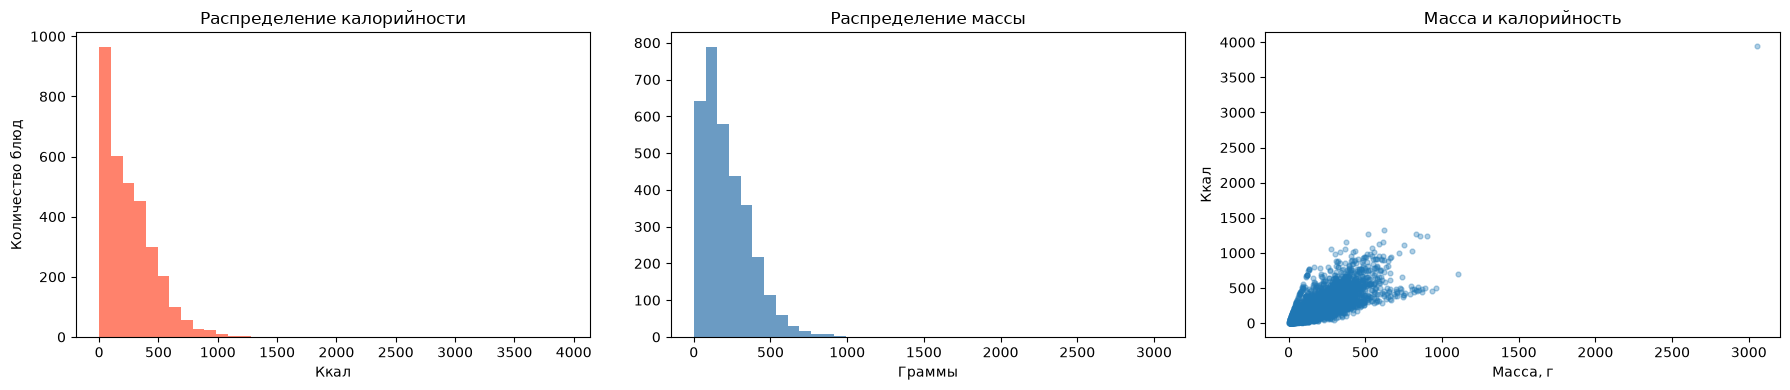

Корреляции:


,total_calories,total_mass
total_calories,1.00,0.76
total_mass,0.76,1.00


,ingredient,dishes
0,olive oil,1561
1,salt,1379
2,garlic,947
3,pepper,723
4,vinegar,713
5,onions,686
6,lemon juice,572
7,arugula,506
8,parsley,493
9,cherry tomatoes,481


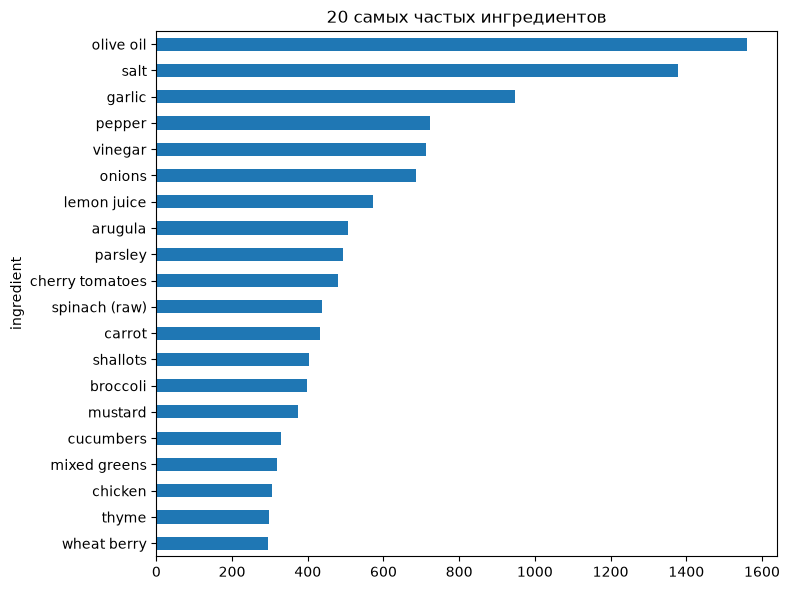

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].hist(metadata.total_calories, bins=40, color='tomato', alpha=0.8)
axes[0].set_title('Распределение калорийности')
axes[0].set_xlabel('Ккал')
axes[0].set_ylabel('Количество блюд')
axes[1].hist(metadata.total_mass, bins=40, color='steelblue', alpha=0.8)
axes[1].set_title('Распределение массы')
axes[1].set_xlabel('Граммы')
axes[2].scatter(metadata.total_mass, metadata.total_calories, alpha=0.35, s=12)
axes[2].set_title('Масса и калорийность')
axes[2].set_xlabel('Масса, г')
axes[2].set_ylabel('Ккал')
plt.tight_layout()
plt.show()

print('Корреляции:')
display(metadata[['total_calories', 'total_mass']].corr().round(3))

ingredient_counter = Counter(
    ingredient.strip()
    for text in metadata.ingredient_text
    for ingredient in text.split(',')
    if ingredient.strip()
)
top_ingredients = pd.DataFrame(ingredient_counter.most_common(20), columns=['ingredient', 'dishes'])
display(top_ingredients)
top_ingredients.sort_values('dishes').plot.barh(x='ingredient', y='dishes', figsize=(8, 6), legend=False)
plt.title('20 самых частых ингредиентов')
plt.tight_layout()
plt.show()

### Выводы по EDA и подход к решению

- Задача является мультимодальной регрессией: одно изображение и текстовый список ингредиентов объединяются перед регрессионной головой.
- Масса порции имеет непосредственную связь с количеством калорий, поэтому используется как дополнительный числовой признак без утечки целевой переменной.
- Для изображений применяются Resize, горизонтальный flip, небольшие поворот/масштабирование и изменение яркости. Сильные геометрические аугментации не используются, чтобы не искажать блюдо.
- Предобученные энкодеры позволяют использовать небольшую выборку эффективнее, чем обучение с нуля. Для стабильности применяются разные learning rate для энкодеров и проекционных/регрессионных слоёв.
- Основная метрика — MAE. Дополнительно выводятся RMSE и R², чтобы видеть влияние больших ошибок и объяснённую вариативность.

> В датасете 3262 блюда: 2755 объектов в исходном train и 507 в test. Все блюда из `dish.csv` имеют соответствующие изображения, поэтому удалять записи из-за отсутствующих файлов не требуется. Для валидации из train дополнительно выделено 413 объектов, итоговое соотношение составляет 2342/413/507.
>
> Средняя калорийность train и test почти одинакова: 254,93 и 255,47 ккал соответственно. Это говорит о сопоставимости выборок по среднему значению. При этом медианная калорийность в test выше, чем в train: 226,01 против 208,12 ккал. Средняя масса порции в test ниже: 198,51 г против 218,01 г в train, поэтому распределения нужно контролировать не только по средним значениям.
>
> Между массой блюда и калорийностью наблюдается заметная положительная корреляция 0,76. Масса является важным признаком, но не объясняет калорийность полностью: блюда одинаковой массы могут существенно различаться по составу и энергетической ценности. Поэтому массу целесообразно передавать в модель как отдельный числовой признак.
>
> Наиболее часто встречаются оливковое масло, соль, чеснок, перец и уксус. Это показывает, что текстовое описание содержит много базовых ингредиентов, встречающихся в большом количестве блюд. Одновременно встречаются редкие и сложные сочетания продуктов, поэтому текстовую часть лучше обрабатывать предобученным языковым энкодером.
>
> На изображениях представлены блюда с разной сложностью состава и размером порции: от простых низкокалорийных блюд до больших многокомпонентных порций. Фотография помогает определить тип блюда и визуальный размер порции, но не позволяет надёжно распознать все ингредиенты или их количество.
>
> Для решения задачи выбран мультимодальный подход: изображение обрабатывается image-энкодером, список ингредиентов — text-энкодером, а масса подаётся как числовой признак. Полученные признаки объединяются и передаются в регрессионную голову с одним выходом. Основная метрика — MAE, дополнительно используются RMSE и R².

## 3. Обучение модели

Весь код обучения находится в `utils.py`, а параметры — в `config.yaml`. Для запуска используется одна функция `train`, поэтому эксперимент можно воспроизвести изменением только конфигурации. На GPU с ограниченной памятью рекомендуется оставить batch size равным 4.

In [5]:
from utils import train

history = train('config.yaml')
display(history)

/home/froschin/work/masters_degree_Roshchin_M25-555/.venv/lib/python3.11/site-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
Loading weights: 100%|██████████| 100/100 [00:00<00:00, 11022.56it/s]
[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/home/froschin/work/masters_degree_Roshchin_M25-555/работа_с_изображениями_и_текстом/2/utils.py:255: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is depre

epoch 01/10 | train MAE 212.04 | val MAE 173.02 | val RMSE 246.80 | val R2 -0.437 | 37.5s
saved best checkpoint: artifacts/best_model.pt


/home/froschin/work/masters_degree_Roshchin_M25-555/работа_с_изображениями_и_текстом/2/utils.py:183: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=amp and device.type == "cuda"):


epoch 02/10 | train MAE 141.36 | val MAE 118.22 | val RMSE 181.11 | val R2 0.226 | 35.6s
saved best checkpoint: artifacts/best_model.pt


/home/froschin/work/masters_degree_Roshchin_M25-555/работа_с_изображениями_и_текстом/2/utils.py:183: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=amp and device.type == "cuda"):


...

/home/froschin/work/masters_degree_Roshchin_M25-555/работа_с_изображениями_и_текстом/2/utils.py:183: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=amp and device.type == "cuda"):


epoch 09/10 | train MAE 61.91 | val MAE 55.24 | val RMSE 90.28 | val R2 0.808 | 36.9s
saved best checkpoint: artifacts/best_model.pt


/home/froschin/work/masters_degree_Roshchin_M25-555/работа_с_изображениями_и_текстом/2/utils.py:183: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=amp and device.type == "cuda"):


epoch 10/10 | train MAE 58.03 | val MAE 57.07 | val RMSE 88.26 | val R2 0.816 | 35.0s


,epoch,train_loss,train_mae,val_loss,val_mae,val_rmse,val_r2,epoch_time_sec
0,1,212.037113,212.037113,173.017774,173.017773,246.803457,-0.436662,37.469564
1,2,141.356226,141.356226,118.223005,118.223005,181.105060,0.226406,35.588229
2,3,103.320025,103.320024,90.805265,90.805265,141.404204,0.528397,37.048869
3,4,87.586056,87.586056,77.503310,77.503311,123.187574,0.642080,37.966859
4,5,79.129652,79.129652,70.107627,70.107627,110.525524,0.711877,37.718117
5,6,73.312033,73.312033,66.638187,66.638188,107.376612,0.728061,35.428508
6,7,69.680062,69.680062,59.439860,59.439860,95.416193,0.785268,36.750141
7,8,65.350296,65.350296,57.413551,57.413551,93.509663,0.793764,39.095947
8,9,61.914507,61.914507,55.240231,55.240232,90.281820,0.807756,36.927037
9,10,58.028353,58.028353,57.070502,57.070503,88.261598,0.816263,35.017087


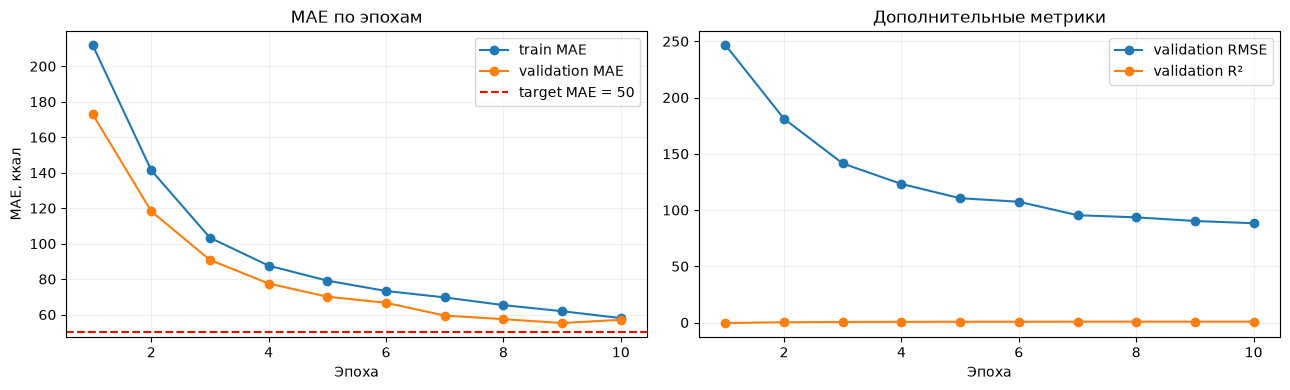

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history.epoch, history.train_mae, marker='o', label='train MAE')
axes[0].plot(history.epoch, history.val_mae, marker='o', label='validation MAE')
axes[0].axhline(50, color='red', linestyle='--', label='target MAE = 50')
axes[0].set_title('MAE по эпохам')
axes[0].set_xlabel('Эпоха')
axes[0].set_ylabel('MAE, ккал')
axes[0].legend()
axes[0].grid(alpha=0.2)
axes[1].plot(history.epoch, history.val_rmse, marker='o', label='validation RMSE')
axes[1].plot(history.epoch, history.val_r2, marker='o', label='validation R²')
axes[1].set_title('Дополнительные метрики')
axes[1].set_xlabel('Эпоха')
axes[1].legend()
axes[1].grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 4. Инференс на test и анализ ошибок

In [7]:
from utils import evaluate_checkpoint

predictions, test_metrics = evaluate_checkpoint('config.yaml')
print(f"Целевая метрика MAE < 50: {'достигнута' if test_metrics['mae'] < 50 else 'не достигнута'}")
display(predictions.head())

/home/froschin/work/masters_degree_Roshchin_M25-555/.venv/lib/python3.11/site-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
Loading weights: 100%|██████████| 100/100 [00:00<00:00, 9471.16it/s]
[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


test MAE: 70.72
test RMSE: 118.68
test R2: 0.687
Целевая метрика MAE < 50: не достигнута


,dish_id,ingredient_text,image_path,actual_calories,predicted_calories,absolute_error
0,dish_1561662216,"soy sauce, garlic, white rice, parsley, onions...",data/images/dish_1561662216/rgb.png,300.794281,395.518829,94.724548
1,dish_1562008979,"jalapenos, lemon juice, pork, wheat berry, cab...",data/images/dish_1562008979/rgb.png,382.936646,479.597168,96.660522
2,dish_1561739238,"egg whites, hash browns, berries, sweet potato",data/images/dish_1561739238/rgb.png,274.190002,392.170044,117.980042
3,dish_1562691032,"berries, olive oil, pineapple, scrambled eggs,...",data/images/dish_1562691032/rgb.png,419.681702,350.955017,68.726685
4,dish_1558549773,spinach (raw),data/images/dish_1558549773/rgb.png,2.300000,-14.464556,16.764556


Целевая метрика MAE < 50: не достигнута

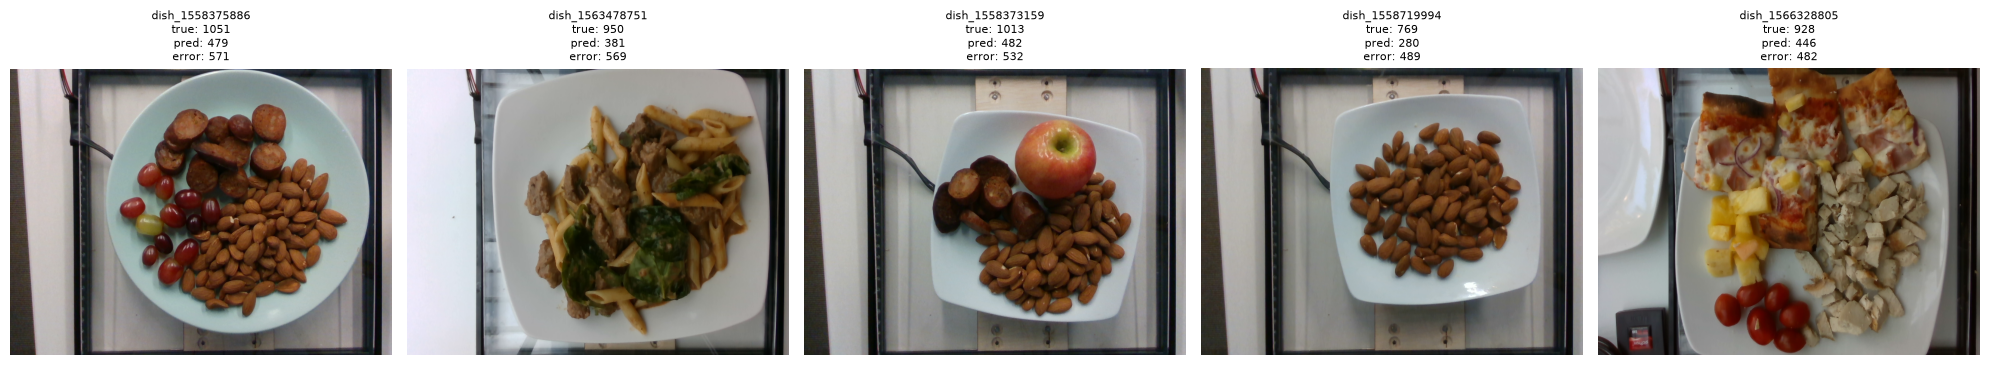

,dish_id,ingredient_text,actual_calories,predicted_calories,absolute_error
0,dish_1558375886,"almonds, sausage, grapes",1050.511108,479.227295,571.283813
1,dish_1563478751,"cream, mushroom, spinach (raw), olive oil, pas...",950.395081,381.171143,569.223938
2,dish_1558373159,"sausage, deprecated, almonds",1013.337036,481.789124,531.547913
3,dish_1558719994,almonds,768.873047,280.297760,488.575287
4,dish_1566328805,"cherry tomatoes, pizza, chicken, pineapple",927.809998,445.818970,481.991028


In [8]:
top5_errors = predictions.sort_values('absolute_error', ascending=False).head(5).reset_index(drop=True)
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
for axis, (_, row) in zip(axes, top5_errors.iterrows()):
    image = Image.open(row.image_path).convert('RGB')
    axis.imshow(image)
    axis.set_title(
        f"{row.dish_id}\ntrue: {row.actual_calories:.0f}\npred: {row.predicted_calories:.0f}\nerror: {row.absolute_error:.0f}",
        fontsize=8,
    )
    axis.axis('off')
plt.tight_layout()
plt.show()

display(top5_errors[['dish_id', 'ingredient_text', 'actual_calories', 'predicted_calories', 'absolute_error']])

### Интерпретация самых больших ошибок

Пять самых больших ошибок имеют общий характер: модель систематически недооценивает блюда с высокой энергетической плотностью.

1. `dish_1558375886`: миндаль, колбаса и виноград. При массе 277 г фактическая калорийность составляет 1050,5 ккал, а модель предсказывает 479,2 ккал. Основная причина — большое количество орехов и колбасы: визуально порция выглядит умеренной, но эти продукты содержат много калорий на грамм.
2. `dish_1563478751`: паста с говядиной, сливками, сметаной, маслом и другими добавками. При массе 545 г фактическая калорийность равна 950,4 ккал, предсказание — 381,2 ккал. На фотографии видны паста, мясо и зелень, но количество масла, сливок и соуса невозможно надёжно определить только по изображению.
3. `dish_1558373159`: миндаль, колбаса и дополнительный ингредиент. При массе 334 г блюдо содержит 1013,3 ккал, тогда как модель оценивает его в 481,8 ккал. Этот пример подтверждает проблему с распознаванием скрытой калорийности орехов и жирных мясных продуктов.
4. `dish_1558719994`: только миндаль, 133 г. Несмотря на небольшую массу и простой состав, фактическая калорийность составляет 768,9 ккал, а предсказание — 280,3 ккал. Для модели это особенно сложный случай: небольшая порция визуально не выглядит калорийной, хотя миндаль имеет высокую калорийность на единицу массы.
5. `dish_1566328805`: пицца, курица, ананас и помидоры, 488 г. Фактическая калорийность равна 927,8 ккал, предсказание — 445,8 ккал. Смешанное блюдо содержит несколько компонентов с разной энергетической плотностью, а визуальная оценка размера и состава порции затруднена.

Таким образом, основные причины ошибок — невозможность восстановить по фотографии точное количество масла, сливок и других калорийных добавок, а также недостаточная представленность энергетически плотных сочетаний в обучающей выборке. Для улучшения качества стоит добавить признак количества ингредиентов, усилить контроль редких ингредиентов, обучать модель на логарифме калорийности или использовать взвешенную функцию потерь, чтобы большие калорийные блюда сильнее влияли на обучение.

## Итог

Обучение устойчиво улучшает качество: validation MAE снизилась с 173,0 на первой эпохе до минимальных 55,24 на девятой эпохе, после чего на десятой эпохе немного выросла до 57,07. Это указывает на достижение почти оптимальной точки обучения и слабые признаки переобучения в конце.

На тестовой выборке получены MAE = 70,72 ккал, RMSE = 118,68 ккал и R² = 0,687. Целевой уровень MAE < 50 не достигнут. При этом R² показывает, что модель объясняет около 69% вариативности калорийности, то есть мультимодальный подход извлекает полезную закономерность, но пока недостаточно точно оценивает крайние и энергетически плотные блюда.

Для следующей итерации рекомендуется использовать early stopping по validation MAE, добавить признаки количества ингредиентов и их энергетической плотности, увеличить долю сложных высококалорийных блюд в обучении и отдельно проверить baseline только по массе. В текущем виде модель можно использовать как ориентировочную оценку калорийности, но для интеграции с требованием MAE < 50 её нужно доработать.